# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en una página de inicio (landing page) con versiónes **A y B** para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de usuarios expuestos a dos versiones de la página de inicio (landing page) dentro del experimento A/B. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.

2. 💰 Comparar el **gasto promedio** por usuario entre la página A y B.

3. 🎯 Comparar la **tasa de conversión** entre la página A y B.

4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión**.

5. 👤 Revisar **la relación entre el tipo de usuario y la conversión**.

6. 📈 **Visualizar los resultados**: Respalda tus conclusiones mediante gráficos claros.

Se aplican **puebas estadísticas apropiados** para comparar las páginas y **recomendar qué versión es mejor**, justificando la decisión con datos.

## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [1]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import ttest_ind



In [3]:
# cargar archivo
df = pd.read_csv('landing_experiment_synthetic.csv')

**Vista previa e información general del conjunto de datos**

In [ ]:
# mostrar las primeras 5 filas
df.head()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [ ]:
# información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


✍️ **Comentario**:
- El dataset cuenta con **40,000 filas y 9 columnas**, y está completo (no tiene valores faltantes).
- La columna `date` está almacenada como texto (`object`) y debe convertirse a formato fecha (`datetime`).
- La columna `landing` es categórica y contiene únicamente las dos variantes esperadas del experimento (`A` y `B`).

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [ ]:
print("Cantidad de usuarios únicos:", df['user_id'].nunique())
print("Total de filas:", len(df))
print("Usuarios duplicados:", df['user_id'].duplicated().sum())

Cantidad de usuarios únicos: 40000
Total de filas: 40000
Usuarios duplicados: 0


**Conclusión:** Se encontraron 40,000 usuarios únicos para un total de 40,000 registros (0 duplicados), lo que confirma que cada usuario fue expuesto a una única versión de la página y garantiza la independencia de los grupos A y B para las pruebas estadísticas posteriores.

 **Variable `date`**  
Explorar rango de fechas. La columna 'date' se cambia de object a datetime

In [ ]:
#Cambio de tipo de dato a fecha de 'date'
df['date'] = pd.to_datetime(df['date'])
print(df.info())
# Resumen estadístico
print(df['date'].describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   user_id         40000 non-null  object        
 1   date            40000 non-null  datetime64[ns]
 2   landing         40000 non-null  object        
 3   region          40000 non-null  object        
 4   dispositivo     40000 non-null  object        
 5   traffic_source  40000 non-null  object        
 6   user_type       40000 non-null  object        
 7   converted       40000 non-null  int64         
 8   gasto           40000 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(6)
memory usage: 2.7+ MB
None
count                   40000
unique                     28
top       2026-01-24 00:00:00
freq                     1512
first     2026-01-01 00:00:00
last      2026-01-28 00:00:00
Name: date, dtype: object


In [ ]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01 00:00:00
Fecha máxima: 2026-01-28 00:00:00


**Variable `gasto` (numérica)**

In [ ]:
# Resumen estadístico
df["gasto"].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [ ]:
# Resumen estadístico de usuarios que se convirtieron
conversion = df[df['converted'] == 1]
conversion.describe()

,converted,gasto
count,5706.0,5706.000000
mean,1.0,65.373668
std,0.0,30.896545
min,1.0,12.120000
25%,1.0,42.950000
50%,1.0,59.860000
75%,1.0,80.370000
max,1.0,303.680000


 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [ ]:
# Explorar variables categóricas y cómo se distribuyen

print("\nConteo de categorías:")
columnas = ['landing', 'region', 'dispositivo', 'traffic_source', 'user_type']
for col in columnas:
    print(df[col].value_counts())



Conteo de categorías:
B    20018
A    19982
Name: landing, dtype: int64
Norte        11166
Centro        9613
Sur           8039
Occidente     6398
Oriente       4784
Name: region, dtype: int64
Mobile     24829
Desktop    15171
Name: dispositivo, dtype: int64
Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: traffic_source, dtype: int64
Nuevo         26033
Recurrente    13967
Name: user_type, dtype: int64


✍️ **Comentario**:

- **Integridad de categorías:** Todas las variables categóricas contienen únicamente valores válidos, sin errores tipográficos ni categorías inesperadas.
- **Balance del experimento (`landing`):** La asignación de usuarios es prácticamente equitativa entre la versión **A** (19,982 usuarios; 49.96%) y la versión **B** (20,018 usuarios; 50.04%), lo que confirma un diseño A/B bien balanceado.
- **Distribución demográfica y de adquisición:** El tráfico proviene principalmente de dispositivos **Mobile** (62.1%) frente a **Desktop** (37.9%), predominan los usuarios **Nuevos** (65.1%) sobre los **Recurrentes** (34.9%), y el canal principal de adquisición es **Organic** (45.0%), seguido por **Ads** (29.8%). En cuanto a geografía, la región **Norte** concentra la mayor participación (27.9%).


## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [ ]:
# Confirmar consistencia entre conversión y gasto
print("No convertidos con gasto > 0:", len(df[(df['converted'] == 0) & (df['gasto'] > 0)]))
print("Convertidos con gasto <= 0:", len(df[(df['converted'] == 1) & (df['gasto'] <= 0)]))

# Gasto por versión
gasto_A = df[(df['landing'] == 'A') & (df['converted'] == 1)]['gasto']
gasto_B= df[(df['landing'] == 'B') & (df['converted'] == 1)]['gasto']

# Verificar cantidad de datos que tiene cada grupo
print('Cantidad de datos landing A', len(gasto_A))
print('Cantidad de datos landing B', len(gasto_B))
print('Gasto promedio landing A', gasto_A.mean())
print('Gasto promedio landing B', gasto_B.mean())
print(gasto_A.describe())
print(gasto_B.describe())

No convertidos con gasto > 0: 0
Convertidos con gasto <= 0: 0
Cantidad de datos landing A 2512
Cantidad de datos landing B 3194
Gasto promedio landing A 61.0865724522293
Gasto promedio landing B 68.74536005009392
count    2512.000000
mean       61.086572
std        28.875470
min        12.120000
25%        40.612500
50%        55.840000
75%        74.837500
max       303.680000
Name: gasto, dtype: float64
count    3194.00000
mean       68.74536
std        32.00102
min        12.98000
25%        45.21000
50%        62.57000
75%        84.27750
max       249.99000
Name: gasto, dtype: float64


### Prueba T

**Hipótesis:**
- **Hipótesis nula (H₀):** Tanto la página (Landing) A como la B generan el mismo gasto promedio.
- **Hipótesis alternativa (H₁):** El gasto promedio es diferente entre las páginas A y B.

In [ ]:
# Verificar dispersión y forma antes de la prueba t
print(f"Grupo A -> Std: {gasto_A.std():.2f} | Varianza: {gasto_A.var():.2f} | Sesgo: {gasto_A.skew():.2f}")
print(f"Grupo B -> Std: {gasto_B.std():.2f} | Varianza: {gasto_B.var():.2f} | Sesgo: {gasto_B.skew():.2f}")

# Aplicar prueba t de Welch (sin asumir varianzas iguales)
t_stat, p_value = ttest_ind(gasto_A, gasto_B, equal_var=False)
print(f"\nEstadístico t: {t_stat:.4f}")
print(f"Valor P: {p_value}")

Grupo A -> Std: 28.88 | Varianza: 833.79 | Sesgo: 1.67
Grupo B -> Std: 32.00 | Varianza: 1024.07 | Sesgo: 1.20

Estadístico t: -9.4810
Valor P: 3.627602231521493e-21


- **Decisión:**

Con un valor p de $3.63 \times 10^{-21}$ (muy inferior a $\alpha = 0.05$), se rechaza la hipótesis nula. Existe evidencia estadística de una diferencia significativa en el gasto promedio entre ambas páginas.
- **Interpretación de negocio:**

La landing B genera un gasto promedio de 68.75 USD frente a 61.09 USD en la landing A. Esto representa un incremento de 7.66 USD por comprador (un aumento aproximado del 12.5%).

- **Verificación de supuestos y justificación de la prueba:**

  - *Normalidad y forma:* Tanto el histograma como el coeficiente de asimetría muestran un sesgo hacia la derecha. Sin embargo, debido al **Teorema del Límite Central** y al gran tamaño de las muestras (n_A = 2,512 USD y n_B = 3,194 USD, muy por encima de n = 30), la distribución de las medias muestrales se aproxima a la normal, haciendo válida la prueba t.
  - *Dispersión y varianzas:* Al tener desviaciones estándar diferentes entre grupos, no se cumple el supuesto estricto de varianzas iguales. Por ello, se configuró **`equal_var=False`** (**prueba t de Welch**), la cual ajusta los grados de libertad de forma robusta.


## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalua si existen diferencias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### Prueba Z

**Hipótesis:**

- **Hipótesis nula (H₀):** Tanto la página (Landing) A como la B presentan la misma tasa de conversión. Cualquier diferencia se debe al azar del muestreo.
- **Hipótesis alternativa (H₁):** La tasa de conversión es diferente entre ambas páginas. Hay un factor que influye en la decisión de compra.


In [ ]:
# Número de usuarios convertidos por página
conversiones = df.groupby('landing')['converted'].sum()

# Total de usuarios por página
totales=df.groupby('landing')['converted'].count()

print("Usuarios convertidos por página:\n", conversiones)
print("\nTotal de usuarios por página:\n", totales)

print(pd.crosstab(df['landing'], df['converted'], normalize='index'))


Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: converted, dtype: int64
converted         0         1
landing                      
A          0.874287  0.125713
B          0.840444  0.159556


In [ ]:
# Aplicar prueba
exitos = [conversiones['A'], conversiones['B']]
observaciones = [totales['A'], totales['B']]
z_stat, p_value = proportions_ztest(exitos , observaciones)

print(f"Estadístico z: {z_stat}")
print(f"Valor p: {p_value}")


Estadístico z: -9.677362674655983
Valor p: 3.7629765627523803e-22



### 📝 Conclusión e interpretación

* **Idoneidad de la prueba:** La prueba Z de dos proporciones es apropiada porque las muestras son independientes (cada usuario fue expuesto a una única versión de la página) y ambos grupos cuentan con un gran volumen de éxitos (conversiones) y fracasos (no conversiones), cumpliendo sobradamente las condiciones para la aproximación normal.
  
* **Decisión:** Con un valor p de $3.76 \times 10^{-22}$ (muy inferior a $\alpha = 0.05$), el resultado es altamente improbable bajo $H_0$, por lo que **se rechaza la hipótesis nula**. El signo negativo del estadístico ($z = -9.68$) simplemente responde al orden en que se ingresaron los grupos en la función (A primero que B) y refleja que la landing A tiene una tasa de conversión menor.
  
* **Interpretación de negocio:** La landing B alcanza una tasa de conversión del **15.96%** frente al **12.57%** de la landing A, lo que representa un incremento de **3.39 puntos porcentuales** (aproximadamente 3.4 puntos porcentuales más, o un aumento relativo del 27%). Se recomienda implementar la versión B.

* **Limitación:** Estos resultados corresponden a una ventana de observación corta de cuatro semanas (28 días), por lo que conviene monitorear si este aumento en la conversión se sostiene a mediano plazo y no responde únicamente a un efecto de novedad.

## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba Prueba Chi-cuadrado

**Hipótesis:**
- **Hipótesis nula (H₀):**  No existe relación entre la fuente de tráfico (traffic_source) y la conversión (converted) de los usuarios de las páginas A y B, pues son independientes.
- **Hipótesis alternativa (H₁):** Sí existe una relación entre lentre la fuente de tráfico (traffic_source) y la conversión (converted) de los usuarios de las páginas A y B para determinar que canáles generan más conversiones.


In [ ]:
# Aplicar prueba
tabla_traffic = pd.crosstab( df["traffic_source"], df["converted"])
tabla_traffic = tabla_traffic.rename(columns={0: 'No Convierte', 1: 'Convierte'})
print(tabla_traffic)
normalize = pd.crosstab( df["traffic_source"], df["converted"], normalize='index')* 100
normalize=normalize.rename(columns={0: 'No Convierte', 1: 'Convierte'})
print(normalize)

chi2_stat, p_value, dof, expected = chi2_contingency(tabla_traffic)

# Verificar frecuencias esperadas (todas deben ser >= 5)
print("\nFrecuencias esperadas:")
print(pd.DataFrame(expected, index=tabla_traffic.index, columns=tabla_traffic.columns).round(1))

# Calcular tamaño del efecto (V de Cramér)
n = tabla_traffic.to_numpy().sum()
min_dim = min(tabla_traffic.shape) - 1
cramers_v = np.sqrt(chi2_stat / (n * min_dim))
print(f"\nTamaño del efecto (V de Cramér): {cramers_v:.4f}")

print(f"Estadístico chi-cuadrado: {chi2_stat:.3f}")
print(f"Valor P: {p_value:.3f}")
print(f"Grados de libertad: {dof}")



converted       No Convierte  Convierte
traffic_source                         
Ads                    10176       1759
Email                   5205        918
Organic                15507       2480
Referral                3406        549
converted       No Convierte  Convierte
traffic_source                         
Ads                85.261835  14.738165
Email              85.007349  14.992651
Organic            86.212264  13.787736
Referral           86.118837  13.881163

Frecuencias esperadas:
converted       No Convierte  Convierte
traffic_source                         
Ads                  10232.5     1702.5
Email                 5249.6      873.4
Organic              15421.2     2565.8
Referral              3390.8      564.2

Tamaño del efecto (V de Cramér): 0.0147
Estadístico chi-cuadrado: 8.662
Valor P: 0.034
Grados de libertad: 3


### 📝 Conclusión e interpretación

* **Supuestos y tamaño del efecto:** Todas las frecuencias esperadas superan ampliamente el mínimo requerido de 5 (la menor es ~564 en Referral), por lo que la prueba de Chi-cuadrado es fiable. Sin embargo, dado el gran tamaño de la muestra ($N = 40,000$), el tamaño del efecto medido por la **V de Cramér es de 0.015**, lo que indica una asociación prácticamente despreciable en la práctica.
  
* **Decisión:** Comparando el valor p ($0.034$) con $\alpha = 0.05$, los conteos observados serían poco probables bajo independencia, por lo que **se rechaza la hipótesis nula**.
  
* **Interpretación de negocio:** Las tasas de conversión por canal (Email 14.99%, Ads 14.74%, Referral 13.88%, Organic 13.79%) varían en apenas ~1.2 puntos porcentuales. Aunque existe una leve ventaja numérica en Email y Ads que vale la pena monitorear en futuras campañas, el comportamiento de conversión se mantiene bastante estable entre todos los canales (y Organic sigue aportando el mayor volumen absoluto de usuarios).


## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba Chi-cuadrado

**Hipótesis:**
- **Hipótesis nula (H₀):**  No existe relación entre el tipo de usuario (user_type: nuevo o recurrente) y la conversión (converted), por lo que son variables independientes.
- **Hipótesis alternativa (H₁):** Sí existe una relación entre el tipo de usuario (user_type) y la conversión (converted), lo que indica que el comportamiento de compra difiere según el historial previo del usuario.

In [ ]:
# Aplicar prueba

# Crear la tabla de contingencia para tipo de usuario y conversión
tabla_user = pd.crosstab(df["user_type"], df["converted"])
tabla_user = tabla_user.rename(columns={0: 'No Convierte', 1: 'Convierte'})
print("Tabla de contingencia absoluta:")
print(tabla_user)

# Calcular proporciones normalizadas por fila (%)
normalize_user = pd.crosstab(df["user_type"], df["converted"], normalize='index') * 100
normalize_user = normalize_user.rename(columns={0: 'No Convierte', 1: 'Convierte'})
print("\nTabla de proporciones (%):")
print(normalize_user)

# Aplicar la prueba de Chi-cuadrada
chi2_stat, p_value, dof, expected = chi2_contingency(tabla_user)
print(f"\nEstadístico chi-cuadrado: {chi2_stat:.3f}")
print(f"Valor P: {p_value:.5f}")
print(f"Grados de libertad: {dof}")

Tabla de contingencia absoluta:
converted   No Convierte  Convierte
user_type                          
Nuevo              22295       3738
Recurrente         11999       1968

Tabla de proporciones (%):
converted   No Convierte  Convierte
user_type                          
Nuevo          85.641301  14.358699
Recurrente     85.909644  14.090356

Estadístico chi-cuadrado: 0.513
Valor P: 0.47363
Grados de libertad: 1


### 📝 Conclusión e interpretación

**Decisión:**  
Como el valor $p$ ($0.474$) es mayor que el nivel de significancia estándar $\alpha = 0.05$, no se puede rechazar la hipótesis nula ($H_0$).

**Interpretación de negocio:**  
No existe evidencia estadística suficiente para afirmar que el tipo de usuario (nuevo vs. recurrente) influya o esté asociado con la tasa de conversión. Ambas categorías convierten prácticamente al mismo nivel (~14.3% vs ~14.1%). Por lo tanto, las estrategias de optimización de la landing page no necesitan segmentarse de manera diferenciada únicamente por este historial previo.

## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

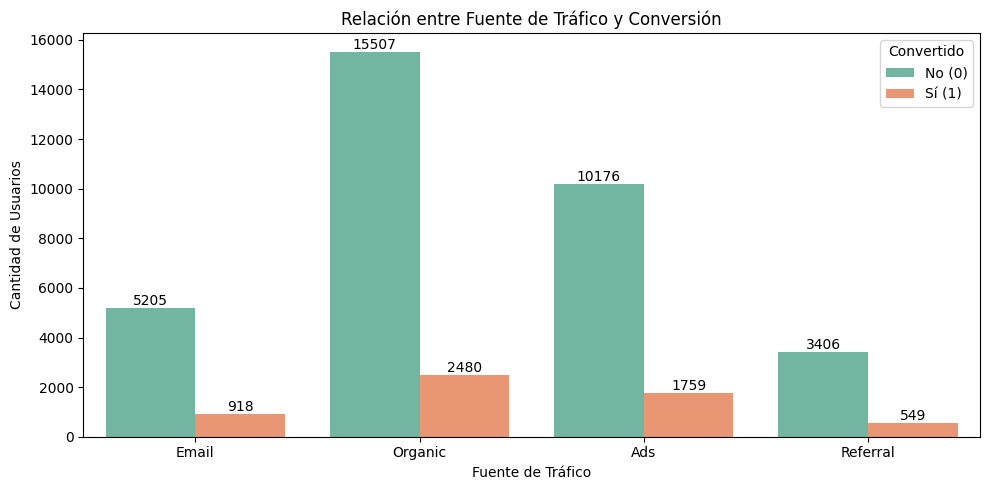

In [ ]:

# 6.1. Relación entre la fuente de tráfico y la conversión
plt.figure(figsize=(10, 5))
ax = sns.countplot(data=df, x='traffic_source', hue='converted', palette='Set2')

# Agregar valores centrados sobre cada barra
for bar in ax.patches:
    height = bar.get_height()
    ax.text(x=bar.get_x() + bar.get_width() / 2,
            y=height,
            s=f'{int(height)}',
            ha='center',
            va='bottom')

plt.title('Relación entre Fuente de Tráfico y Conversión')
plt.xlabel('Fuente de Tráfico')
plt.ylabel('Cantidad de Usuarios')
plt.legend(title='Convertido', labels=['No (0)', 'Sí (1)'])
plt.tight_layout()
plt.show()


✍️ **Comentario**:
El gráfico
 de barras muestra la distribución absoluta de conversiones por canal. Aunque el tráfico orgánico (Organic) aporta el mayor volumen total de usuarios y conversiones debido a su tamaño de muestra, los canales de pago (Ads) y correo (Email) presentan proporciones de conversión ligeramente superiores (~14.7% y ~15.0% respectivamente), lo cual respalda la asociación estadística encontrada en la prueba Chi-cuadrada.

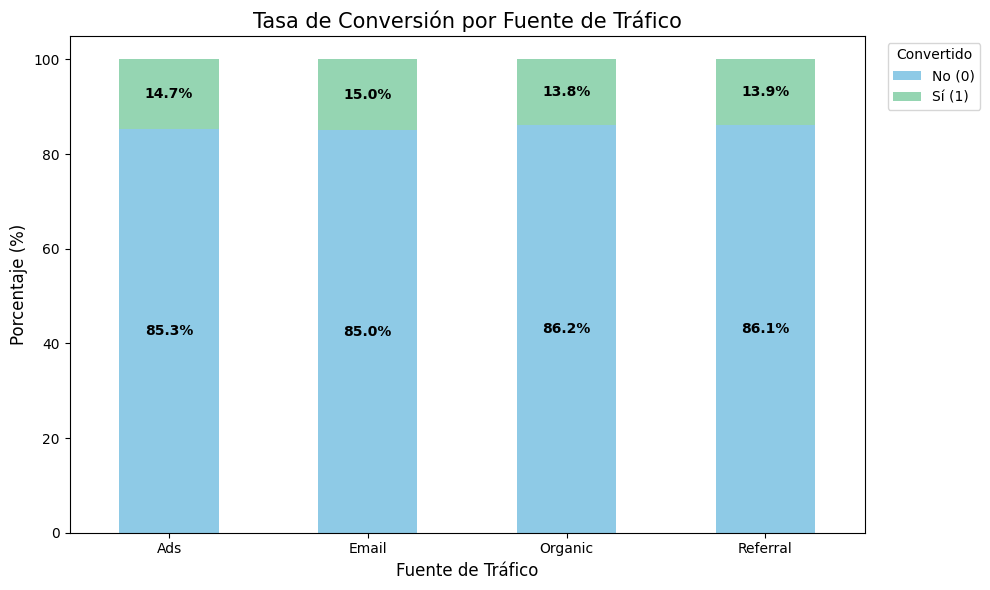

In [ ]:
# Gráfico de barras apiladas normalizadas
tabla_t_source = pd.crosstab(df['traffic_source'], df['converted'], normalize='index') * 100
ax = tabla_t_source.plot(kind='bar', stacked=True, figsize=(10, 6), color=["#8ecae6", "#95d5b2"])

# Agregar etiquetas de porcentaje centradas en cada segmento de la barra
for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    x, y = p.get_xy()
    ax.text(x + width / 2,
            y + height / 2,
            f'{height:.1f}%',
            ha='center',
            va='center',
            fontsize=10,
            fontweight='bold')

plt.title('Tasa de Conversión por Fuente de Tráfico', fontsize=15)
plt.ylabel('Porcentaje (%)', fontsize=12)
plt.xlabel('Fuente de Tráfico', fontsize=12)
plt.xticks(rotation=0)
# Mover la leyenda fuera del área del gráfico para no tapar las barras
plt.legend(title='Convertido', labels=['No (0)', 'Sí (1)'], bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

✍️ **Comentario**:
El gráfico permite ver de forma directa el porcentaje exacto de conversión en cada canal de tráfico sin que la diferencia en el volumen total de usuarios afecte la lectura.
**Variación mínima entre canales**: A primera vista, las barras muestran que la proporción de color verde claro (usuarios que sí convirtieron, 1) se mantiene muy similar en todas las fuentes de tráfico, rondando siempre entre el 13.8% y el 15.0%.
Email (Email): Presenta la tasa de conversión más alta del experimento con un 15.0% (es decir, el color verde ocupa una fracción levemente mayor en su barra).
Aunque existen ligeras variaciones de rendimiento entre los canales de adquisición, el comportamiento general de compra se mantiene bastante estable en todos los puntos de contacto.

### Relación entre el tipo de usuario y la conversión

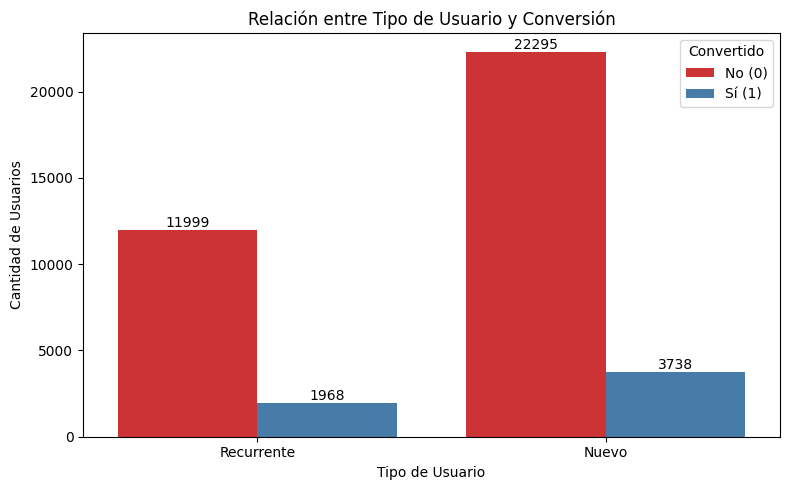

In [ ]:
# 6.2. Relación entre el tipo de usuario y la conversión
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='user_type', hue='converted', palette='Set1')

# Agregar valores centrados sobre cada barra
for bar in ax.patches:
    height = bar.get_height()
    if height > 0:  # Evitar mostrar ceros innecesarios
        ax.text(x=bar.get_x() + bar.get_width() / 2,
                y=height,
                s=f'{int(height)}',
                ha='center',
                va='bottom')

plt.title('Relación entre Tipo de Usuario y Conversión')
plt.xlabel('Tipo de Usuario')
plt.ylabel('Cantidad de Usuarios')
plt.legend(title='Convertido', labels=['No (0)', 'Sí (1)'])
plt.tight_layout()
plt.show()

✍️ **Comentario**: La gráfica muestra los conteos absolutos por tipo de usuario y evidencia que el segmento Nuevo aporta casi el doble de volumen total que el Recurrente. Sin embargo, al comparar visualmente la altura de la barra de conversiones (azul) frente a la de no conversiones (roja) dentro de cada grupo, se observa que mantienen una relación muy similar. Esto respalda gráficamente el resultado de la prueba estadística anterior ($p = 0.474$), donde no se encontró evidencia suficiente de que el historial previo del usuario altere su probabilidad de compra.

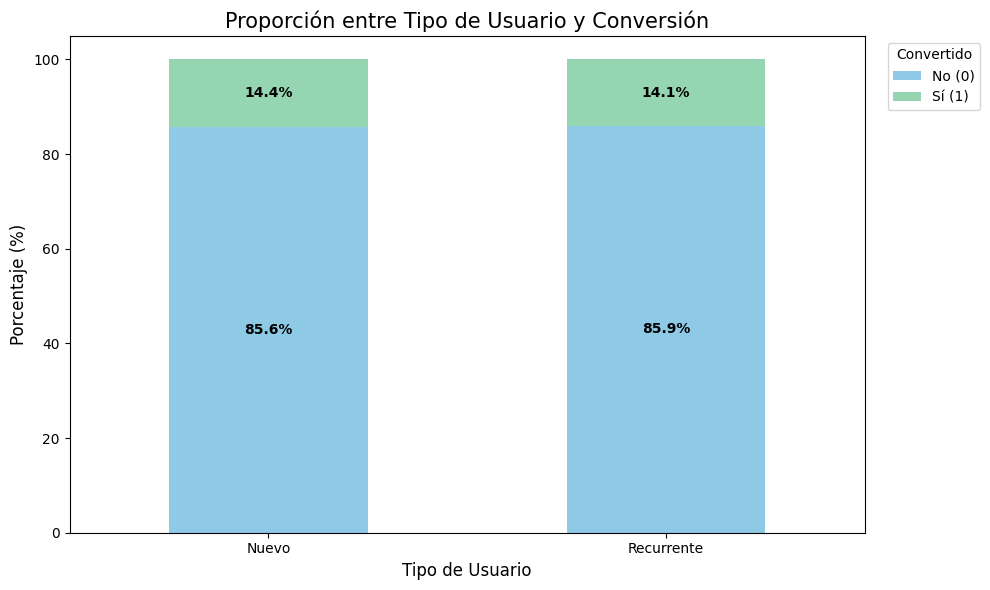

In [ ]:

# Gráfico de barras apiladas normalizadas
tabla_user_type = pd.crosstab(df['user_type'], df['converted'], normalize='index') * 100
ax = tabla_user_type.plot(kind='bar', stacked=True, figsize=(10, 6), color=["#8ecae6", "#95d5b2"])

# Agregar etiquetas de porcentaje centradas en cada segmento de la barra
for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    x, y = p.get_xy()
    ax.text(x + width / 2,
            y + height / 2,
            f'{height:.1f}%',
            ha='center',
            va='center',
            fontsize=10,
            fontweight='bold')

plt.title('Proporción entre Tipo de Usuario y Conversión', fontsize=15)
plt.ylabel('Porcentaje (%)', fontsize=12)
plt.xlabel('Tipo de Usuario', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Convertido', labels=['No (0)', 'Sí (1)'], bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

✍️ **Comentario**:En la gráfica, al observar las barras de los usuarios Nuevos y Recurrentes, la distribución de los colores es prácticamente idéntica. Ambas barras muestran que el segmento de color verde claro (usuarios que sí convirtieron, 1) se detiene casi en el mismo punto, rondando el **14.1% - 14.4%**.

Este gráfico es la representación visual directa de por qué la prueba de Chi-cuadrada anterior arrojó un valor $p$ alto ($0.474$). Como no hay una divergencia visual apreciable entre las barras, se respalda gráficamente que **no hay evidencia de que la conversión dependa del historial previo del usuario**.

Esto sugiere a los tomadores de decisiones que la landing page convierte de manera muy similar sin importar si el visitante ya conocía la plataforma previamente o si es su primera vez. Por lo tanto, no es necesario gastar recursos diferenciando la experiencia de la página basándose únicamente en si el usuario es nuevo o recurrente.

## 🧩 Paso 7. Insight Ejecutivo para Stakeholders

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**  
- ¿Qué página genera mayor conversión y gasto promedio?  
- ¿Qué canales de tráfico son más efectivos para generar conversiones?  
- ¿Existen diferencias significativas según el tipo de usuario?  
- ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?


---

## 7.1. 🌟 Insight Ejecutivo basado en el Experimento A/B

### 7.1.1. 🔍 Comparación de página (A vs B)

*- **Gasto promedio por comprador:** La versión B genera un promedio de **68.75 USD** frente a **61.09 USD** en la versión A, lo que representa un incremento de **7.66 USD más por comprador** (un aumento del 12.5%).
  - *Respaldo estadístico:* Prueba t de Welch con $t = -9.48$ y $p = 3.63 \times 10^{-21} < 0.05$ (se rechaza la igualdad de medias).
- **Tasa de conversión:** La versión B convierte al **15.96%** frente al **12.57%** de la versión A (una mejora de aproximadamente **3.4 puntos porcentuales**).
  - *Respaldo estadístico:* Prueba Z de dos proporciones con $z = -9.68$ y $p = 3.76 \times 10^{-22} < 0.05$ (se rechaza la igualdad de proporciones).

### 7.1.2. 📊 Segmentación por fuente de tráfico y tipo de usuario

* **Fuente de tráfico:** Las tasas de conversión se mantienen bastante estables entre canales, oscilando en apenas ~1.2 puntos porcentuales: **Email (14.99%)**, **Ads (14.74%)**, **Referral (13.88%)** y **Organic (13.79%)**. Aunque la prueba de Chi-cuadrado arroja significancia estadística por el gran tamaño de muestra ($\chi^2 = 8.662$, $p = 0.034$, $gl = 3$), el tamaño del efecto es muy pequeño ($V \text{ de Cramér} = 0.015$). Email y Ads muestran un rendimiento ligeramente superior que vale la pena monitorear, mientras que Organic sigue aportando el mayor volumen total de usuarios.
* **Tipo de usuario:** Los usuarios nuevos (**14.36%**) y recurrentes (**14.09%**) convierten prácticamente al mismo ritmo ($\chi^2 = 0.513$, $p = 0.474$, $gl = 1$). No existe evidencia de que el historial previo del usuario afecte su probabilidad de conversión.

### 7.1.3. ⚠️ Limitaciones del análisis

* **Comparación solo entre compradores:** El análisis de gasto evalúa únicamente a los usuarios que realizaron una compra (5,706 compradores), no el ingreso promedio por usuario expuesto. Dado que B convierte a más visitantes, ambos grupos de compradores podrían tener perfiles ligeramente distintos.
* **Duración de la prueba:** El experimento abarca una ventana corta de **28 días** (4 semanas), por lo que conviene dar seguimiento para confirmar que la mejora de B se sostiene en el tiempo y no responde a un efecto temporal de novedad.

### 7.1.4. 💡 Recomendaciones de negocio

* **Implementar la variante B:** Dado que los datos respaldan un desempeño superior tanto en conversión (+3.4 puntos porcentuales) como en gasto promedio (+$7.66 USD por comprador), se recomienda desplegar la versión B de la landing page como versión principal.
* **Evitar segmentación por historial previo:** Al no encontrarse diferencias según el tipo de usuario (nuevo vs. recurrente), no es necesario invertir recursos en personalizar la landing page bajo este criterio.
* **Monitorear canales de adquisición:** Aunque el desempeño entre canales es homogéneo, vale la pena observar el comportamiento de **Email** y **Ads** en futuras campañas para evaluar si su ligera ventaja en conversión se mantiene y resulta rentable frente a su costo de adquisición.